In [ ]:
# This exploratory notebook lives in visualization/exploratory/ but all paths
# below are relative to the repository root, so make that the working directory.
import os
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results").is_dir())
os.chdir(ROOT)
print("working directory:", ROOT)


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import os

In [56]:
cross = pd.read_excel('results/metrics/dnabertS/pairwise_Egovirales_vs_Mriyavirales/cross_1→2_fwd_fwd_matrix.xlsx')
pk1 = pd.read_excel('results/metrics/dnabertS/pairwise_Egovirales_vs_Mriyavirales/pk_fwd_1_in_2_matrix.xlsx')
pk2 = pd.read_excel('results/metrics/dnabertS/pairwise_Egovirales_vs_Mriyavirales/pk_fwd_2_in_1_matrix.xlsx')

In [61]:
pk = pk1.copy()

for col in pk:
    pk[col] = (pk1[col] + pk2[col])/2

In [62]:
pk

,layer,sample_5,sample_2,sample_24,sample_4,sample_7,sample_21,sample_8,sample_3,sample_15,...,sample_43,sample_46,sample_49,sample_40,sample_41,sample_48,sample_36,sample_38,sample_39,sample_47
0,0.0,0.321847,0.322148,0.336175,0.325033,0.332683,0.334195,0.336324,0.332316,0.325619,...,0.325765,0.327557,0.342292,0.333007,0.339265,0.319284,0.332530,0.330590,0.319959,0.339172
1,1.0,0.409758,0.407367,0.418609,0.410944,0.418638,0.418316,0.418026,0.416560,0.412276,...,0.407873,0.410831,0.427332,0.417344,0.427667,0.409736,0.422195,0.418833,0.413847,0.419107
2,2.0,0.474370,0.472445,0.487702,0.473684,0.483928,0.481225,0.486548,0.476505,0.481807,...,0.477739,0.479378,0.490824,0.483962,0.494463,0.477710,0.489527,0.488540,0.482786,0.483194
3,3.0,0.504966,0.502294,0.518590,0.504578,0.517246,0.516128,0.511611,0.503708,0.508678,...,0.509423,0.506149,0.519628,0.513738,0.520802,0.512631,0.510617,0.513985,0.511183,0.514541
4,4.0,0.523270,0.515863,0.527881,0.518805,0.531660,0.531143,0.518204,0.508780,0.515475,...,0.520686,0.515799,0.532433,0.529727,0.530973,0.525333,0.521440,0.519510,0.524686,0.523776
5,5.0,0.522236,0.515029,0.524807,0.519956,0.531154,0.527485,0.514388,0.507448,0.517824,...,0.520986,0.511165,0.531277,0.531490,0.528857,0.527411,0.520208,0.517303,0.525940,0.520899
6,6.0,0.529413,0.520537,0.527944,0.527131,0.536887,0.533904,0.524999,0.510805,0.521019,...,0.524986,0.518975,0.539164,0.538829,0.532790,0.532335,0.523716,0.522489,0.531124,0.523082
7,7.0,0.523503,0.517123,0.527548,0.525612,0.532859,0.531376,0.522313,0.513701,0.522552,...,0.523538,0.518268,0.531531,0.532514,0.534381,0.528589,0.521754,0.524087,0.528657,0.522888
8,8.0,0.514982,0.506863,0.517359,0.514183,0.518673,0.523126,0.509582,0.500541,0.513179,...,0.514246,0.510878,0.520337,0.524057,0.520063,0.515678,0.513126,0.511146,0.518964,0.511102
9,9.0,0.506385,0.494859,0.509553,0.504586,0.507261,0.512380,0.500881,0.492104,0.504292,...,0.506030,0.502544,0.513954,0.511378,0.510725,0.508798,0.504171,0.502212,0.511993,0.500281


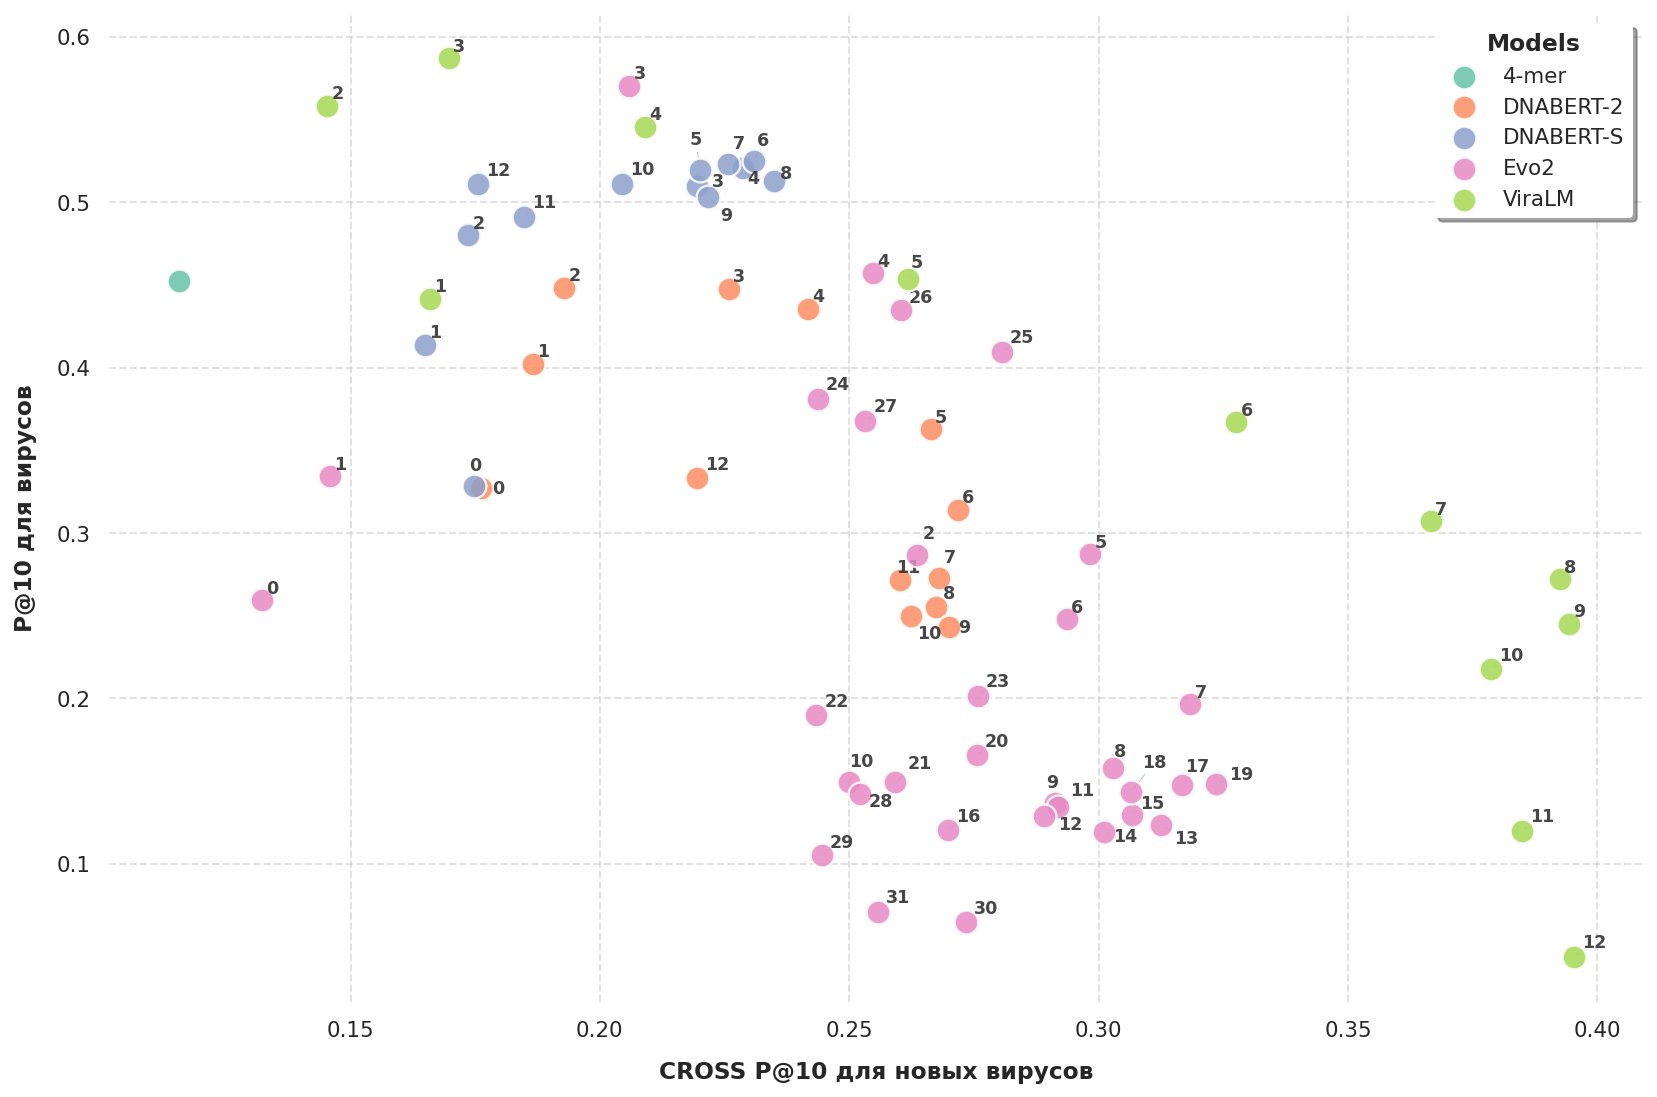

In [67]:
import re
from adjustText import adjust_text  # Автоматически решает проблему наложения текста
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Словарь для красивого переименования моделей
model_mapping = {
    "kmer": "4-mer",
    "evo2": "Evo2",
    "dnabert2": "DNABERT-2",
    "dnabertS": "DNABERT-S",
    "viralm": "ViraLM",
}

models = ["kmer", "dnabert2", "dnabertS", "evo2", "viralm"]

# Настройка красивого стиля
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.family": "sans-serif", "figure.dpi": 140})

fig, ax = plt.subplots(figsize=(12, 8))

# Будем использовать качественную палитру цветов
colors = sns.color_palette("Set2", len(models))
texts = []  # Список для хранения всех объектов текста для adjustText

for mod, color in zip(models, colors):
    # Загрузка данных
    cross = pd.read_excel(
        f"results/metrics/{mod}/pairwise_Egovirales_vs_Mriyavirales/cross_1→2_fwd_fwd_matrix.xlsx"
    )
    pk1 = pd.read_excel(
        f"results/metrics/{mod}/pairwise_Egovirales_vs_Mriyavirales/pk_fwd_1_in_2_matrix.xlsx"
    )
    pk2 = pd.read_excel(
        f"results/metrics/{mod}/pairwise_Egovirales_vs_Mriyavirales/pk_fwd_2_in_1_matrix.xlsx"
    )

    pk = pk1.copy()

    # Исправлено: перебираем только числовые колонки, пропуская 'layer'
    for col in pk.columns.drop("layer", errors="ignore"):
        try:
            pk[col] = (pk1[col] + pk2[col]) / 2
        except Exception as e:
            print(e)

    # Расчет средних
    pk_mean = pd.DataFrame(pk.drop(columns=["layer"]).mean(axis=1))
    cross_mean = pd.DataFrame(cross.drop(columns=["layer"]).mean(axis=1))

    pk_mean["layer"] = pk["layer"]
    cross_mean["layer"] = cross["layer"]

    # Красивое отображаемое имя модели
    display_name = model_mapping.get(mod, mod)

    # 1. Строим увеличенные точки (s=150 вместо 70) с красивой обводкой
    ax.scatter(
        cross_mean[0],
        pk_mean[0],
        label=display_name,
        color=color,
        s=150,  # <-- ЗДЕСЬ увеличен размер точек
        alpha=0.85,
        edgecolors="white",
        linewidth=1.2,  # Немного утолщена обводка для баланса с размером
        zorder=3,
    )

    # 2. Собираем подписи слоев
    for x, y, layer in zip(
        cross_mean[0], pk_mean[0], cross_mean["layer"]
    ):
        layer_num = "".join(re.findall(r"\d+", str(layer)))

        t = ax.text(
            x,
            y,
            layer_num,
            fontsize=9,  # Чуть-чуть увеличили шрифт для читаемости рядом с большими точками
            fontweight="semibold",
            color="#333333",  # Сделали цвет текста капельку контрастнее
            alpha=0.9,
        )
        texts.append(t)

# 3. Автоматическое распределение подписей
# Настройки expand изменены на (1.4, 1.6), чтобы текст сильнее «отталкивался» от крупных точек
adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.5, alpha=0.5),
    expand=(1.4, 1.6),
)

# Оформление осей и подписей
ax.set_xlabel("CROSS P@10 для новых вирусов", fontsize=12, fontweight="bold", labelpad=10)
ax.set_ylabel("P@10 для вирусов", fontsize=12, fontweight="bold", labelpad=10)

# Настройка легенды
ax.legend(
    title="Models",
    title_fontproperties={"weight": "bold"},
    loc="upper right",
    frameon=True,
    facecolor="white",
    edgecolor="none",
    shadow=True,
)

# Тонкая настройка сетки для читаемости
ax.grid(True, linestyle="--", alpha=0.6, zorder=0)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.savefig("figures/exploratory/PK_cross_beautiful.png", bbox_inches="tight")
plt.show()


In [50]:
!pip install adjustText

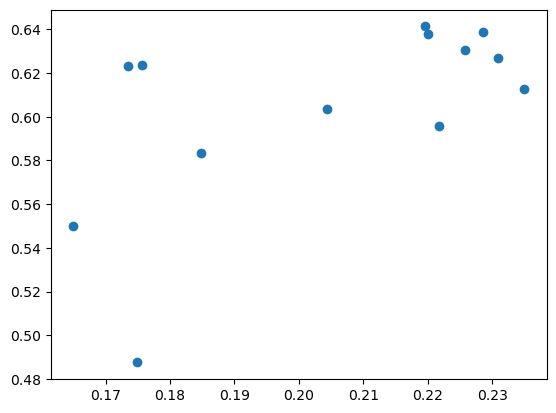

In [42]:
plt.scatter(cross_mean[0], pk_mean[0])